# MAP2 vs MAP2 + Tuj1: soma, reconstruction and network statistics

Each **Mech** image (DAPI, MAP2, Piezo1, Tuj1) is reconstructed twice with the same accepted somas and settings:
**MAP2** only (`segment_neurons.py --sigma 2 --map2-only`, tag `_sigma2`) and **MAP2 + Tuj1** (default, tag `_sigma2_map2-tuj1`).
Sections 2–5 compare the two versions (paired: the same images, the same somas). Section 1 describes the somas of the Mech images
(they do not depend on the segmentation). **ID** images are not used.
Section 6 compares the network activity of the soma-only and the morphology (MAP2 + Tuj1) networks.

Every **Mech** image folder in `data/` (`_Mech_` in the name) processed by the pipeline is picked up automatically:

1. `Image_Processor.py` → `auto_cells.npy` (DAPI nuclei classified with MAP2), `somas_data.npy` (accepted neuron somas)
2. `segment_neurons.py --sigma 2 [--map2-only]` → `neuron_segmentation<tag>.tiff`, `neuron_labels<tag>.tiff`
3. `NeuronSkeletonizer.py --tag <tag>` → `morphologies<tag>/*.swc`
4. `bsb_network.py --tag <tag>` → `results/network/<stem><tag>/` (section 6)

Images missing a step are listed and skipped for that part. Per-image numbers are cached in `results/presentation/cache/`
(delete a file there after re-running the pipeline on that image). Figures and tables go to `results/presentation/`.

**Caveats**
- Statistics use **one value per image** (images are the replicates; neurons of one image are not independent). MAP2 vs MAP2 + Tuj1 is
  tested with a paired Wilcoxon signed-rank test on the images: with 3 images the smallest possible two-sided p is 0.25, so the tests
  cannot reach significance; look at the paired lines and the per-image ratios.

In [1]:
import os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')  # all paths below are relative to the repo root

import os, glob, json, re
import numpy as np
import pandas as pd
import tifffile as tiff
from scipy import ndimage, stats
import matplotlib.pyplot as plt

DATA = 'data'
OUT = 'results/presentation'
ZFILL = False          # True: use the outputs segmented with --fill-z-support 0.5 (tag _zfill0.5) when present
SHOLL_STEP_UM = 5.0
SHOLL_MAX_UM = 120.0
FAR_FROM_SOMA_UM = 10.0  # neuron volume farther than this from the soma centre = "neurite volume"
STAINS = {'ID': '#1b9e77', 'Mech': '#d95f02'}                 # section 1 (somas): per stain
ZTAG = '_zfill0.5' if ZFILL else ''
TUJ1_TAGS = {'MAP2': '_sigma2' + ZTAG, 'MAP2 + Tuj1': '_sigma2' + ZTAG + '_map2-tuj1'}   # segmentation versions of the Mech images
GROUPS = {'MAP2': '#7570b3', 'MAP2 + Tuj1': '#d95f02'}         # sections 2-4: per segmentation version
os.makedirs(os.path.join(OUT, 'cache'), exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 11, 'axes.labelsize': 10})

In [2]:
def group_of(name):
    if re.search('_mech_', name, re.I):
        return 'Mech'
    if re.search('_id_', name, re.I):
        return 'ID'
    return None

def tag_of(folder, names):
    """Output tag of segment_neurons.py --sigma 2 for this image (Tuj1 added for Mech stains)."""
    tag = '_sigma2' + ('_zfill0.5' if ZFILL else '') + ('_map2-tuj1' if 'tuj1' in names else '')
    return tag if os.path.exists(os.path.join(folder, f'neuron_labels{tag}.tiff')) else None

images = []
for folder in sorted(glob.glob(os.path.join(DATA, '*', 'processed_metadata.npy'))):
    folder = os.path.dirname(folder)
    name = os.path.basename(folder)
    grp = group_of(name)
    if grp != 'Mech':          # ID images are not used (only MAP2 vs MAP2 + Tuj1 on Mech)
        continue
    meta = np.load(os.path.join(folder, 'processed_metadata.npy'), allow_pickle=True).item()
    names = meta.get('channel_names') or []
    tag = tag_of(folder, names)
    images.append({'image': name, 'group': grp, 'folder': folder, 'tag': tag, 'channels': names, 'xy_res': meta['xy_res'],
                   'z_res': meta['z_res'], 'shape_zyx': (meta['z_px'], meta['height_px'], meta['width_px']),
                   'has_cells': os.path.exists(os.path.join(folder, 'auto_cells.npy')),
                   'has_swc': tag is not None and os.path.isdir(os.path.join(folder, f'morphologies{tag}'))})
recons = []   # Mech images, one entry per segmentation version (group = version)
for im in images:
    if im['group'] != 'Mech':
        continue
    for g, t in TUJ1_TAGS.items():
        if os.path.exists(os.path.join(im['folder'], f'neuron_labels{t}.tiff')):
            recons.append({**im, 'group': g, 'tag': t, 'has_swc': os.path.isdir(os.path.join(im['folder'], f'morphologies{t}'))})
        else:
            print(f"no {g} reconstruction for {im['image']} (tag {t})")
display(pd.DataFrame(images)[['image', 'group', 'tag', 'has_cells', 'has_swc', 'channels']])
pd.DataFrame(recons)[['image', 'group', 'tag', 'has_swc']]

,image,group,tag,has_cells,has_swc,channels
0,IF_D14_Mech_40x_up_Ch1_002,Mech,_sigma2_map2-tuj1,True,True,"[dapi, map2, piezo1, tuj1, ch5]"
1,IF_D14_Mech_40x_up_Ch1_003,Mech,_sigma2_map2-tuj1,True,True,"[dapi, map2, piezo1, tuj1, ch5]"
2,IF_D14_Mech_40x_up_Ch1_004,Mech,_sigma2_map2-tuj1,True,True,"[dapi, map2, piezo1, tuj1, ch5]"


,image,group,tag,has_swc
0,IF_D14_Mech_40x_up_Ch1_002,MAP2,_sigma2,True
1,IF_D14_Mech_40x_up_Ch1_002,MAP2 + Tuj1,_sigma2_map2-tuj1,True
2,IF_D14_Mech_40x_up_Ch1_003,MAP2,_sigma2,True
3,IF_D14_Mech_40x_up_Ch1_003,MAP2 + Tuj1,_sigma2_map2-tuj1,True
4,IF_D14_Mech_40x_up_Ch1_004,MAP2,_sigma2,True
5,IF_D14_Mech_40x_up_Ch1_004,MAP2 + Tuj1,_sigma2_map2-tuj1,True


## Per-image statistics (cached)

In [3]:
def soma_stats(im):
    """Cell proposals (auto_cells.npy: class 0 neuron / 1 astrocyte / 2 other, Ki67+ flag) and accepted cells."""
    f = im['folder']
    area_mm2 = im['shape_zyx'][1] * im['shape_zyx'][2] * im['xy_res'] ** 2 / 1e6
    has_ki67, has_actin = 'ki67' in im['channels'], 'actin' in im['channels']
    s = {'area_mm2': area_mm2, 'ki67_measured': has_ki67, 'astro_measured': has_actin}
    if im['has_cells']:
        c = np.load(os.path.join(f, 'auto_cells.npy'))
        cls, ki = c[:, 4].astype(int), c[:, 5] > 0
        s.update(nuclei=len(c), prop_neurons=int(((cls == 0) & ~ki).sum()),
                 prop_astrocytes=int(((cls == 1) & ~ki).sum()) if has_actin else np.nan,
                 ki67_pos=int(ki.sum()) if has_ki67 else np.nan, others=int(((cls == 2) & ~ki).sum()))
    s['accepted_neurons'] = len(np.load(os.path.join(f, 'somas_data.npy'))) if os.path.exists(os.path.join(f, 'somas_data.npy')) else np.nan
    a = os.path.join(f, 'astrocytes_data.npy')
    s['accepted_astrocytes'] = len(np.load(a)) if os.path.exists(a) else (0 if has_actin else np.nan)
    return s


def read_swc(path):
    a = np.loadtxt(path, comments='#', ndmin=2)
    return a[:, 2:5], a[:, 5], a[:, 6].astype(int) - 1   # xyz um, radius um, parent index (-1 root... -2 after shift)


def swc_stats(path):
    xyz, rad, par = read_swc(path)
    par = np.where(par < 0, -1, par)
    n = len(par)
    nchild = np.bincount(par[1:], minlength=n)
    seg = np.r_[0, np.linalg.norm(xyz[1:] - xyz[par[1:]], axis=1)]
    soma_r = rad[0]
    seg[1:][par[1:] == 0] = np.maximum(0, seg[1:][par[1:] == 0] - soma_r)   # stems start at the soma surface
    # path length from the soma and branch (section) lengths between branch points / tips
    path = np.zeros(n)
    for i in range(1, n):
        path[i] = path[par[i]] + seg[i]
    ends = np.flatnonzero((nchild != 1) & (np.arange(n) > 0))           # branch points and tips end a section
    sections = []
    for e in ends:
        L, v = 0.0, e
        while v > 0:
            L += seg[v]; v = par[v]
            if v == 0 or nchild[v] > 1:
                break
        sections.append(L)
    d = np.linalg.norm(xyz - xyz[0], axis=1)
    radii = np.arange(SHOLL_STEP_UM, SHOLL_MAX_UM + 1e-9, SHOLL_STEP_UM)
    dc, dp = d[1:], d[par[1:]]
    sholl = [int(((np.minimum(dc, dp) < r) & (np.maximum(dc, dp) >= r)).sum()) for r in radii]
    return {'length_um': float(seg.sum()), 'stems': int(nchild[0]), 'branch_points': int((nchild[1:] > 1).sum()),
            'tips': int((nchild[1:] == 0).sum()), 'max_reach_um': float(d.max()), 'max_path_um': float(path.max()),
            'mean_section_um': float(np.mean(sections)) if sections else 0.0, 'soma_radius_um': float(soma_r),
            'mean_neurite_radius_um': float(rad[1:].mean()) if n > 1 else np.nan, 'sholl': sholl}


def recon_stats(im):
    """Per-image segmentation numbers and per-neuron volumes (labels) + SWC statistics."""
    f, tag = im['folder'], im['tag']
    vox = im['xy_res'] ** 2 * im['z_res']
    seg = tiff.imread(os.path.join(f, f'neuron_segmentation{tag}.tiff')) > 0
    lab = tiff.imread(os.path.join(f, f'neuron_labels{tag}.tiff'))
    labelled = lab > 0
    img = {'seg_fraction': float(seg.mean()), 'seg_volume_um3': float(seg.sum() * vox),
           'unassigned_fraction': float((seg & ~labelled).sum() / seg.sum()),
           'labelled_outside_seg_um3': float((labelled & ~seg).sum() * vox), 'n_labels': int(len(np.unique(lab)) - 1)}
    neurons = []
    for k, sl in enumerate(ndimage.find_objects(lab), start=1):
        if sl is None:
            continue
        m = lab[sl] == k
        zz, yy, xx = np.nonzero(m)
        pos = np.c_[(zz + sl[0].start) * im['z_res'], (yy + sl[1].start) * im['xy_res'], (xx + sl[2].start) * im['xy_res']]
        row = {'label': k, 'volume_um3': float(m.sum() * vox), 'z_extent_um': float((np.ptp(zz) + 1) * im['z_res'])}
        swc = os.path.join(f, f'morphologies{tag}', f'neuron_{k}.swc')
        if os.path.exists(swc):
            st = swc_stats(swc)
            soma_xyz = read_swc(swc)[0][0]
            far = np.linalg.norm(pos - soma_xyz[::-1], axis=1) > FAR_FROM_SOMA_UM   # pos is (z, y, x) um, SWC is (x, y, z)
            row.update(st, neurite_volume_um3=float(far.sum() * vox))
        neurons.append(row)
    return img, neurons


def cached(im):
    path = os.path.join(OUT, 'cache', f"{im['image']}{im['tag'] or ''}.json")
    if os.path.exists(path):
        return json.load(open(path))
    out = {'soma': soma_stats(im)}
    if im['tag'] is not None:
        out['image'], out['neurons'] = recon_stats(im)
    json.dump(out, open(path, 'w'), default=lambda v: None if isinstance(v, float) and np.isnan(v) else v)
    print('computed', path)
    return out

res = {im['image']: cached(im) for im in images}                    # somas (+ default reconstruction)
rec_res = {(r['image'], r['group']): cached(r) for r in recons}      # Mech, both versions

In [4]:
# somas: one row per image (group = stain)
df_img = pd.DataFrame([{'image': im['image'], 'group': im['group'], **res[im['image']]['soma']} for im in images]).set_index('image')
df_img = df_img.astype({c: float for c in ['prop_astrocytes', 'ki67_pos', 'accepted_astrocytes']}, errors='ignore')
for c in ['nuclei', 'prop_neurons', 'prop_astrocytes', 'ki67_pos', 'others', 'accepted_neurons', 'accepted_astrocytes']:
    df_img[c + '_per_mm2'] = df_img[c] / df_img['area_mm2']
# reconstructions: one row per (Mech image, version), neurons per (image, version, label)
rec_rows, neuron_rows = [], []
for r in recons:
    out = rec_res[(r['image'], r['group'])]
    rec_rows.append({'image': r['image'], 'group': r['group'], 'tag': r['tag'], **out['image']})
    neuron_rows += [{'image': r['image'], 'group': r['group'], **n} for n in out['neurons']]
df_rec = pd.DataFrame(rec_rows)
df_neu = pd.DataFrame(neuron_rows)
per_img = df_neu.groupby(['image', 'group']).agg(neurons=('label', 'size'), median_volume_um3=('volume_um3', 'median'),
                                                 median_length_um=('length_um', 'median'), median_branch_points=('branch_points', 'median'),
                                                 median_tips=('tips', 'median'), median_stems=('stems', 'median'),
                                                 median_reach_um=('max_reach_um', 'median'), median_section_um=('mean_section_um', 'median'),
                                                 median_neurite_volume_um3=('neurite_volume_um3', 'median'))
df_rec = df_rec.join(per_img, on=['image', 'group'])
df_rec['seg_percent'] = df_rec['seg_fraction'] * 100
df_rec['unassigned_percent'] = df_rec['unassigned_fraction'] * 100
display(df_img[['group', 'nuclei', 'prop_neurons', 'others', 'accepted_neurons']])
df_rec[['image', 'group', 'seg_percent', 'unassigned_percent', 'neurons', 'median_volume_um3', 'median_length_um']]

,group,nuclei,prop_neurons,others,accepted_neurons
image,,,,,
IF_D14_Mech_40x_up_Ch1_002,Mech,277,131,146,125
IF_D14_Mech_40x_up_Ch1_003,Mech,259,130,129,130
IF_D14_Mech_40x_up_Ch1_004,Mech,410,166,244,170


,image,group,seg_percent,unassigned_percent,neurons,median_volume_um3,median_length_um
0,IF_D14_Mech_40x_up_Ch1_002,MAP2,1.776791,10.100329,122,2978.092512,186.528013
1,IF_D14_Mech_40x_up_Ch1_002,MAP2 + Tuj1,2.725008,14.897332,122,3475.148321,269.244262
2,IF_D14_Mech_40x_up_Ch1_003,MAP2,1.635853,11.122277,128,2218.666600,102.255332
3,IF_D14_Mech_40x_up_Ch1_003,MAP2 + Tuj1,2.835231,13.660867,128,2492.874707,146.792423
4,IF_D14_Mech_40x_up_Ch1_004,MAP2,1.465598,15.458679,167,1583.672306,92.854660
5,IF_D14_Mech_40x_up_Ch1_004,MAP2 + Tuj1,2.655644,15.471761,167,2233.967103,152.515002


## Helpers: group plots with one point per image
`df_img` (somas, Mech, one row per image) or `df_rec` (reconstructions, groups = versions, one row per image and
version, paired: the two versions of one image are joined by a line and tested with a paired Wilcoxon test).

In [5]:
def group_order(data=None, groups=None):
    data = df_rec if data is None else data
    groups = GROUPS if groups is None else groups
    return [g for g in groups if g in set(data['group'])]


def is_paired(data):
    return 'image' in data.columns          # df_rec / per-image medians: one row per (image, version)


def group_test(col, data=None, groups=None, min_n=3):
    """(p, test name) or (None, ''). Paired data: Wilcoxon signed-rank on the images present in both groups; else Mann-Whitney."""
    data = df_rec if data is None else data
    g = group_order(data, groups)
    if len(g) != 2:
        return None, ''
    if is_paired(data):
        w = data.pivot(index='image', columns='group', values=col).reindex(columns=g).astype(float).dropna()
        if len(w) < min_n or (w[g[0]] == w[g[1]]).all():
            return None, ''
        return stats.wilcoxon(w[g[0]], w[g[1]]).pvalue, f'paired Wilcoxon, n={len(w)}'
    a, b = (data.loc[data['group'] == x, col].astype(float).dropna() for x in g)
    if len(a) < min_n or len(b) < min_n:
        return None, ''
    return stats.mannwhitneyu(a, b).pvalue, 'Mann-Whitney'


def annotate_p(ax, p, test):
    if p is not None:
        ax.annotate(f'{test}: p = {p:.3g}', xy=(0.5, 1.0), xycoords='axes fraction', ha='center', va='bottom', fontsize=8,
                    xytext=(0, 3), textcoords='offset points', color='0.3')
        ax.set_title(ax.get_title(), pad=18)   # room for the p-value line between axes and title


def per_image_plot(ax, col, label, data=None, groups=None):
    """Bar = group mean, error = SD, dots = images (paired data: the versions of one image joined by a line). NaN = not measured."""
    data = df_rec if data is None else data
    groups = GROUPS if groups is None else groups
    order = group_order(data, groups)
    paired = is_paired(data)
    for i, g in enumerate(order):
        vv = data.loc[data['group'] == g, col].astype(float).dropna()
        if len(vv) == 0:
            ax.text(i, 0, 'not\nmeasured', ha='center', va='bottom', fontsize=8, color='0.4')
            continue
        ax.bar(i, vv.mean(), color=groups[g], alpha=0.35, width=0.6, yerr=vv.std(ddof=1) if len(vv) > 1 else None, capsize=4)
        x = np.full(len(vv), i) if paired else i + np.random.default_rng(0).uniform(-0.12, 0.12, len(vv))
        ax.scatter(x, vv, color=groups[g], s=22, zorder=3, edgecolor='k', lw=0.4)
    if paired:
        for _, s in data.groupby('image'):
            ax.plot(range(len(order)), s.set_index('group').reindex(order)[col].astype(float).values, color='0.5', lw=0.8, zorder=2)
    ax.set_xticks(range(len(order)), [f"{g}\n(n={int((data['group'] == g).sum())})" for g in order])
    ax.set_xlim(-0.6, len(order) - 0.4)
    ax.set_title(label)
    annotate_p(ax, *group_test(col, data, groups))


def per_neuron_plot(ax, col, label, log=False):
    """Violin of all neurons per version + median of each image (dots, the two versions of one image joined)."""
    order = group_order()
    for i, g in enumerate(order):
        v = df_neu.loc[df_neu['group'] == g, col].dropna()
        if len(v) == 0:
            continue
        vals = np.log10(v[v > 0]) if log else v
        parts = ax.violinplot(vals, positions=[i], widths=0.7, showextrema=False)
        for pc in parts['bodies']:
            pc.set_facecolor(GROUPS[g]); pc.set_alpha(0.35)
        ax.hlines(np.median(vals), i - 0.25, i + 0.25, color='k', lw=1)
    meds = df_neu.groupby(['image', 'group'])[col].median().rename('m').reset_index()
    if log:
        meds['m'] = np.log10(meds['m'])
    for _, s in meds.groupby('image'):
        y = s.set_index('group').reindex(order)['m'].values
        ax.plot(range(len(order)), y, color='0.5', lw=0.8, zorder=2)
        ax.scatter(range(len(order)), y, color=[GROUPS[g] for g in order], s=26, zorder=3, edgecolor='k', lw=0.4)
    ax.set_xticks(range(len(order)), [f"{g}\n({int((df_neu['group'] == g).sum())} neurons)" for g in order])
    ax.set_title(label + (' (log10)' if log else ''))
    p, test = group_test('m', meds)
    annotate_p(ax, p, f'per-image medians, {test}' if p is not None else '')


def save(fig, name):
    fig.tight_layout()
    for ext in ('png', 'pdf'):
        fig.savefig(os.path.join(OUT, f'{name}.{ext}'), bbox_inches='tight')

## 1. Soma statistics (Mech)
The somas do not depend on the segmentation (Tuj1 is not used to find them): they are the same for MAP2 and MAP2 + Tuj1.
Nuclei found in DAPI and classified: **neurons** (MAP2 shell), **others** (no MAP2 around). *Accepted* = somas kept after review in napari.

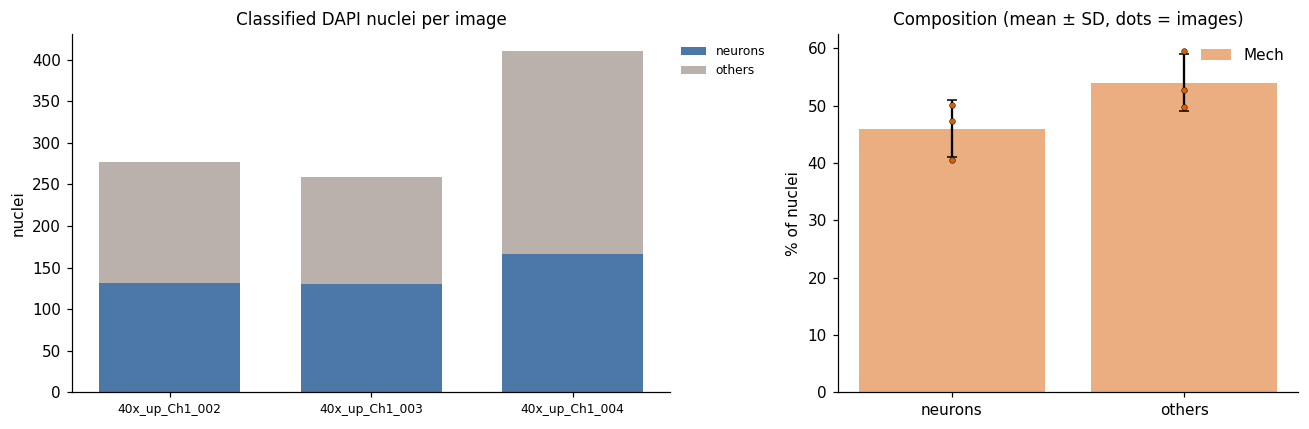

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1.3, 1]})
cats = [('prop_neurons', 'neurons', '#4c78a8'), ('others', 'others', '#bab0ac')]
ax = axs[0]
order = df_img.sort_values('group').index
bottom = np.zeros(len(order))
for c, lab, col in cats:
    v = df_img.loc[order, c].astype(float).fillna(0).values
    ax.bar(range(len(order)), v, bottom=bottom, color=col, label=lab, width=0.7)
    bottom += v
ax.set_xticks(range(len(order)), [re.sub('^IF_D14_(ID|Mech)_', '', i).strip('_') for i in order], fontsize=8)
ax.set_ylabel('nuclei'); ax.set_title('Classified DAPI nuclei per image'); ax.legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1.0, 1.0))
ax = axs[1]
frac = df_img[[c for c, _, _ in cats]].div(df_img['nuclei'], axis=0) * 100
so = group_order(df_img, STAINS)
w = 0.8 / len(so)
for j, g in enumerate(so):
    sub = frac[df_img['group'] == g]
    m = sub.mean()
    ax.bar(np.arange(len(cats)) + (j - (len(so) - 1) / 2) * w, m.values, w, color=STAINS[g], alpha=0.5, label=g,
           yerr=sub.std(ddof=1).values if len(sub) > 1 else None, capsize=3)
    for k, (c, _, _) in enumerate(cats):
        ax.scatter(np.full(len(sub), k + (j - (len(so) - 1) / 2) * w), sub[c], color=STAINS[g], s=14, edgecolor='k', lw=0.3, zorder=3)
ax.set_xticks(range(len(cats)), [l for _, l, _ in cats]); ax.set_ylabel('% of nuclei'); ax.set_title('Composition (mean ± SD, dots = images)')
ax.legend(frameon=False)
save(fig, 'fig1_soma_composition')

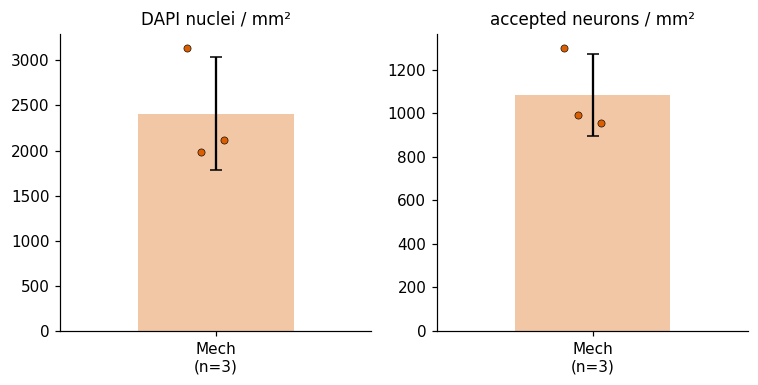

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(7, 3.6))
per_image_plot(axs[0], 'nuclei_per_mm2', 'DAPI nuclei / mm²', data=df_img, groups=STAINS)
per_image_plot(axs[1], 'accepted_neurons_per_mm2', 'accepted neurons / mm²', data=df_img, groups=STAINS)
save(fig, 'fig2_soma_densities')

## 2. Reconstruction: segmentation and neuron volumes (Mech: MAP2 vs MAP2 + Tuj1)
*Segmentation* = voxels kept by the k-means segmentation; *unassigned* = segmented voxels not reached from any accepted soma by the
watershed (neurites of non-accepted cells, isolated pieces). *Neurite volume* = neuron volume farther than 10 µm from its soma centre.

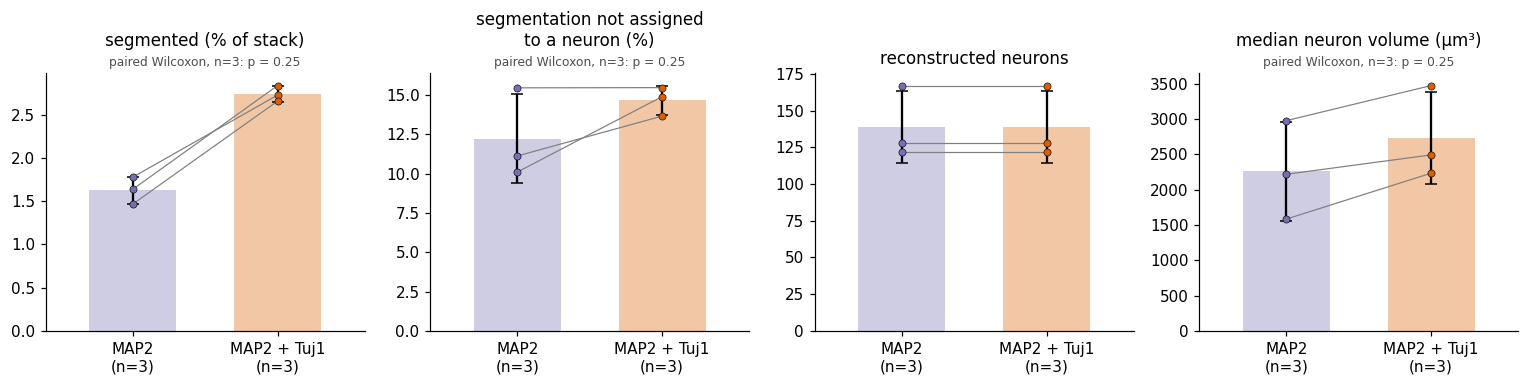

In [8]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6))
per_image_plot(axs[0], 'seg_percent', 'segmented (% of stack)')
per_image_plot(axs[1], 'unassigned_percent', 'segmentation not assigned\nto a neuron (%)')
per_image_plot(axs[2], 'neurons', 'reconstructed neurons')
per_image_plot(axs[3], 'median_volume_um3', 'median neuron volume (µm³)')
save(fig, 'fig3_segmentation')

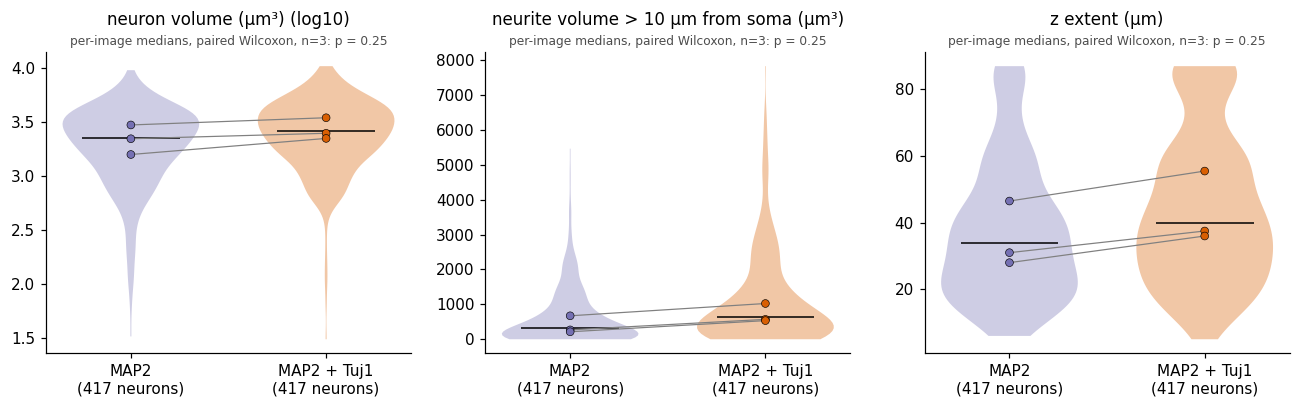

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
per_neuron_plot(axs[0], 'volume_um3', 'neuron volume (µm³)', log=True)
per_neuron_plot(axs[1], 'neurite_volume_um3', f'neurite volume > {FAR_FROM_SOMA_UM:g} µm from soma (µm³)')
per_neuron_plot(axs[2], 'z_extent_um', 'z extent (µm)')
save(fig, 'fig4_neuron_volumes')

## 3. Morphology (SWC skeletons; Mech: MAP2 vs MAP2 + Tuj1)
Total length (stems from the soma surface), branch points, tips, primary neurites (stems), maximal reach (straight distance soma → farthest point),
mean section length (between branch points / tips). Sholl: number of skeleton crossings of spheres centred on the soma.

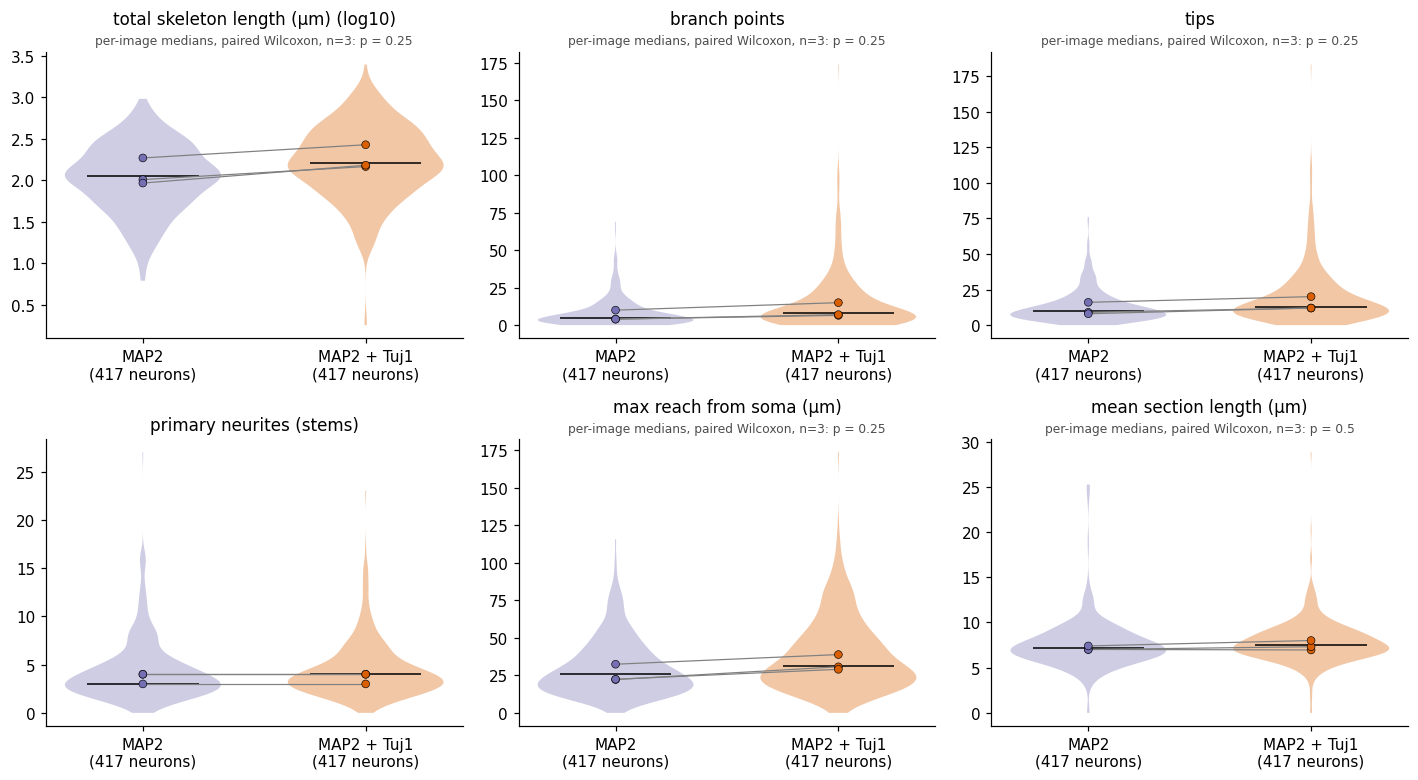

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7.2))
for ax, (c, l, lg) in zip(axs.ravel(), [('length_um', 'total skeleton length (µm)', True), ('branch_points', 'branch points', False),
                                         ('tips', 'tips', False), ('stems', 'primary neurites (stems)', False),
                                         ('max_reach_um', 'max reach from soma (µm)', False), ('mean_section_um', 'mean section length (µm)', False)]):
    per_neuron_plot(ax, c, l, log=lg)
save(fig, 'fig5_morphology')

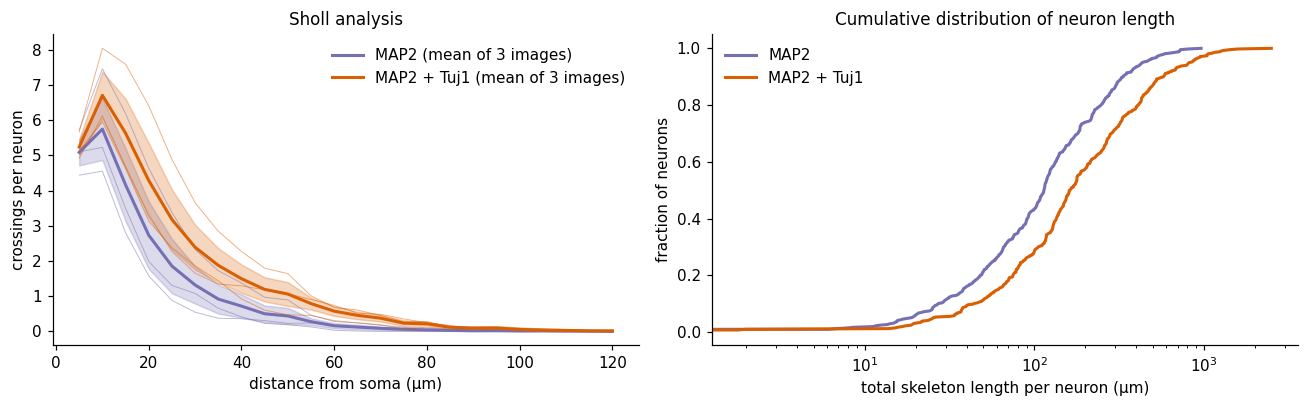

In [11]:
radii = np.arange(SHOLL_STEP_UM, SHOLL_MAX_UM + 1e-9, SHOLL_STEP_UM)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for g in group_order():
    sub = df_neu[(df_neu['group'] == g) & df_neu['sholl'].notna()]
    per_image = np.array([np.mean(np.stack(s['sholl'].values), axis=0) for _, s in sub.groupby('image')])
    m = per_image.mean(0)
    axs[0].plot(radii, m, color=GROUPS[g], lw=2, label=f'{g} (mean of {len(per_image)} images)')
    if len(per_image) > 1:
        sem = per_image.std(0, ddof=1) / np.sqrt(len(per_image))
        axs[0].fill_between(radii, m - sem, m + sem, color=GROUPS[g], alpha=0.25)
    for row in per_image:
        axs[0].plot(radii, row, color=GROUPS[g], lw=0.6, alpha=0.5)
    # cumulative distribution of total length
    L = np.sort(sub['length_um'].values)
    axs[1].plot(L, np.arange(1, len(L) + 1) / len(L), color=GROUPS[g], lw=2, label=g)
axs[0].set_xlabel('distance from soma (µm)'); axs[0].set_ylabel('crossings per neuron'); axs[0].set_title('Sholl analysis'); axs[0].legend(frameon=False)
axs[1].set_xscale('log'); axs[1].set_xlabel('total skeleton length per neuron (µm)'); axs[1].set_ylabel('fraction of neurons')
axs[1].set_title('Cumulative distribution of neuron length'); axs[1].legend(frameon=False)
save(fig, 'fig6_sholl_length_cdf')

## 4. Summary tables (one value per image, mean ± SD per group)
Somas: Mech. Reconstructions: Mech MAP2 vs MAP2 + Tuj1, with the mean ± SD of the per-image ratio (MAP2 + Tuj1 / MAP2).

In [12]:
def summary_table(cols, data, groups):
    order = group_order(data, groups)
    rows = {}
    for c, l in cols.items():
        r = {}
        for g in order:
            v = data.loc[data['group'] == g, c].astype(float).dropna()
            r[g] = 'not measured' if len(v) == 0 else (f'{v.mean():.3g}' if len(v) == 1 else f'{v.mean():.3g} ± {v.std(ddof=1):.2g}')
        if is_paired(data) and len(order) == 2:
            w = data.pivot(index='image', columns='group', values=c).reindex(columns=order).astype(float).dropna()
            q = w[order[1]] / w[order[0]]
            r[f'ratio {order[1]} / {order[0]}'] = '' if len(q) == 0 else (f'{q.mean():.3g}' if len(q) == 1 else f'{q.mean():.3g} ± {q.std(ddof=1):.2g}')
        p, test = group_test(c, data, groups)
        r['test'], r['p'] = test, '' if p is None else f'{p:.3g}'
        rows[l] = r
    return pd.DataFrame(rows).T


soma_cols = {'nuclei_per_mm2': 'DAPI nuclei / mm²', 'accepted_neurons_per_mm2': 'neurons / mm²'}
rec_cols = {'seg_percent': 'segmented %', 'unassigned_percent': 'unassigned %', 'neurons': 'neurons',
            'median_volume_um3': 'neuron volume µm³ (median)', 'median_neurite_volume_um3': 'neurite volume µm³ (median)',
            'median_length_um': 'skeleton length µm (median)', 'median_branch_points': 'branch points (median)', 'median_tips': 'tips (median)',
            'median_stems': 'stems (median)', 'median_reach_um': 'reach µm (median)', 'median_section_um': 'section length µm (median)'}
soma_summary = summary_table(soma_cols, df_img, STAINS)
summary = summary_table(rec_cols, df_rec, GROUPS)
soma_summary.to_csv(os.path.join(OUT, 'summary_soma_by_stain.csv'))
summary.to_csv(os.path.join(OUT, 'summary_by_version.csv'))
df_img.drop(columns=['folder'], errors='ignore').to_csv(os.path.join(OUT, 'per_image.csv'))
df_rec.to_csv(os.path.join(OUT, 'per_image_reconstruction.csv'), index=False)
df_neu.drop(columns=['sholl']).to_csv(os.path.join(OUT, 'per_neuron.csv'), index=False)
display(soma_summary)
summary

,Mech,test,p
DAPI nuclei / mm²,2.41e+03 ± 6.3e+02,,
neurons / mm²,1.08e+03 ± 1.9e+02,,


,MAP2,MAP2 + Tuj1,ratio MAP2 + Tuj1 / MAP2,test,p
segmented %,1.63 ± 0.16,2.74 ± 0.091,1.69 ± 0.14,"paired Wilcoxon, n=3",0.25
unassigned %,12.2 ± 2.8,14.7 ± 0.93,1.23 ± 0.24,"paired Wilcoxon, n=3",0.25
neurons,139 ± 24,139 ± 24,1 ± 0,,
neuron volume µm³ (median),2.26e+03 ± 7e+02,2.73e+03 ± 6.5e+02,1.23 ± 0.15,"paired Wilcoxon, n=3",0.25
neurite volume µm³ (median),385 ± 2.5e+02,709 ± 2.7e+02,2.05 ± 0.49,"paired Wilcoxon, n=3",0.25
skeleton length µm (median),127 ± 52,190 ± 69,1.51 ± 0.12,"paired Wilcoxon, n=3",0.25
branch points (median),6 ± 3.5,9.5 ± 4.8,1.62 ± 0.12,"paired Wilcoxon, n=3",0.25
tips (median),11 ± 4.4,14.7 ± 4.6,1.36 ± 0.13,"paired Wilcoxon, n=3",0.25
stems (median),3.67 ± 0.58,3.67 ± 0.58,1 ± 0,,
reach µm (median),25.7 ± 5.8,32.8 ± 5.3,1.29 ± 0.092,"paired Wilcoxon, n=3",0.25


## 5. Neuron by neuron (Mech: MAP2 vs MAP2 + Tuj1)
Both Mech versions use the same soma seeds (the separation always runs on MAP2), so **label k is the same soma in both versions**
(checked below on the SWC soma nodes): neurons can be compared one by one.

Needs, per Mech image: `segment_neurons.py data/<stem>/ --sigma 2 --map2-only` and `NeuronSkeletonizer.py data/<stem>/ --tag _sigma2`.

In [13]:
VERSIONS = {'Mech (MAP2)': GROUPS['MAP2'], 'Mech (MAP2 + Tuj1)': GROUPS['MAP2 + Tuj1']}   # colours of the figure below


def tuj1_overlap(im):
    """Voxel-level comparison of the two Mech versions (cached): what Tuj1 adds and where it goes."""
    path = os.path.join(OUT, 'cache', f"{im['image']}_tuj1_overlap.json")
    if os.path.exists(path):
        return json.load(open(path))
    f = im['folder']
    (tm, tu) = TUJ1_TAGS.values()
    seg_m = tiff.imread(os.path.join(f, f'neuron_segmentation{tm}.tiff')) > 0
    seg_u = tiff.imread(os.path.join(f, f'neuron_segmentation{tu}.tiff')) > 0
    lab_m = tiff.imread(os.path.join(f, f'neuron_labels{tm}.tiff'))
    lab_u = tiff.imread(os.path.join(f, f'neuron_labels{tu}.tiff'))
    tuj_only = seg_u & ~seg_m
    both = (lab_m > 0) & (lab_u > 0)
    out = {'seg_map2': int(seg_m.sum()), 'seg_union': int(seg_u.sum()), 'map2_missing_in_union': int((seg_m & ~seg_u).sum()),
           'tuj1_only_fraction_of_union': float(tuj_only.sum() / seg_u.sum()),
           'tuj1_only_assigned_fraction': float(((lab_u > 0) & tuj_only).sum() / tuj_only.sum()),
           'same_label_where_both_labelled': float((lab_m[both] == lab_u[both]).mean()),
           'labelled_map2': int((lab_m > 0).sum()), 'labelled_union': int((lab_u > 0).sum())}
    # per neuron: share of its MAP2-only voxels kept by the same label, and share of its union volume that is Tuj1-only
    n = int(max(lab_m.max(), lab_u.max())) + 1
    vm = np.bincount(lab_m.ravel(), minlength=n)
    keep = np.bincount(lab_m[both][lab_m[both] == lab_u[both]], minlength=n)
    vu = np.bincount(lab_u.ravel(), minlength=n)
    tu_only = np.bincount(lab_u[tuj_only], minlength=n)
    out['neurons'] = [{'label': k, 'kept_fraction': float(keep[k] / vm[k]) if vm[k] else None,
                       'tuj1_only_fraction': float(tu_only[k] / vu[k]) if vu[k] else None} for k in range(1, n)]
    json.dump(out, open(path, 'w'))
    print('computed', path)
    return out


tuj_neu, tuj_ovl = [], {}
for im in images:
    if im['group'] != 'Mech' or 'tuj1' not in im['channels']:
        continue
    if not all(os.path.isdir(os.path.join(im['folder'], f'morphologies{t}')) for t in TUJ1_TAGS.values()):
        print('skipped (needs both versions + SWC):', im['image'])
        continue
    for v, t in TUJ1_TAGS.items():
        r = cached({**im, 'tag': t})
        tuj_neu += [{'image': im['image'], 'version': f'Mech ({v})', **n} for n in r['neurons']]
    tuj_ovl[im['image']] = tuj1_overlap(im)
    # same soma = same label: the SWC soma nodes of the two versions must coincide
    swc_m, swc_u = (os.path.join(im['folder'], f'morphologies{t}') for t in TUJ1_TAGS.values())
    common = sorted(set(os.listdir(swc_m)) & set(os.listdir(swc_u)) - {'summary.csv'})
    d = [np.linalg.norm(read_swc(os.path.join(swc_m, s))[0][0] - read_swc(os.path.join(swc_u, s))[0][0]) for s in common]
    d = np.array(d)
    print(f"{im['image']}: {len(common)} neurons in both versions; soma nodes within 3 um: {(d < 3).sum()}, "
          f"moved: {', '.join(f'{s} ({x:.0f} um)' for s, x in zip(common, d) if x >= 3) or 'none'} "
          f"(labels that do not contain their soma seed: the tree is rooted at the thickest point); "
          f"same label where both labelled: {tuj_ovl[im['image']]['same_label_where_both_labelled'] * 100:.1f}%")

pd.DataFrame(tuj_ovl).T.drop(columns='neurons')

IF_D14_Mech_40x_up_Ch1_002: 122 neurons in both versions; soma nodes within 3 um: 122, moved: none (labels that do not contain their soma seed: the tree is rooted at the thickest point); same label where both labelled: 99.7%
IF_D14_Mech_40x_up_Ch1_003: 128 neurons in both versions; soma nodes within 3 um: 126, moved: neuron_26.swc (29 um), neuron_32.swc (52 um) (labels that do not contain their soma seed: the tree is rooted at the thickest point); same label where both labelled: 99.1%
IF_D14_Mech_40x_up_Ch1_004: 167 neurons in both versions; soma nodes within 3 um: 158, moved: neuron_10.swc (12 um), neuron_139.swc (7 um), neuron_15.swc (44 um), neuron_2.swc (19 um), neuron_21.swc (8 um), neuron_25.swc (3 um), neuron_47.swc (9 um), neuron_56.swc (53 um), neuron_6.swc (7 um) (labels that do not contain their soma seed: the tree is rooted at the thickest point); same label where both labelled: 99.7%


,seg_map2,seg_union,map2_missing_in_union,tuj1_only_fraction_of_union,tuj1_only_assigned_fraction,same_label_where_both_labelled,labelled_map2,labelled_union
IF_D14_Mech_40x_up_Ch1_002,6558113,10057969,20,0.34797,0.693738,0.996781,12099749,14302758
IF_D14_Mech_40x_up_Ch1_003,4253985,7372929,0,0.423026,0.749134,0.991393,10247124,12076359
IF_D14_Mech_40x_up_Ch1_004,5409505,9801948,207,0.448141,0.741584,0.996623,10578547,13741596


Same label = same soma. Points above the diagonal grew when Tuj1 was added.
*Kept* = share of the neuron's MAP2-only voxels that keep the same label with Tuj1 (low = territory taken by a neighbour);
*Tuj1-only* = share of the neuron's MAP2 + Tuj1 volume that is segmented in Tuj1 only.

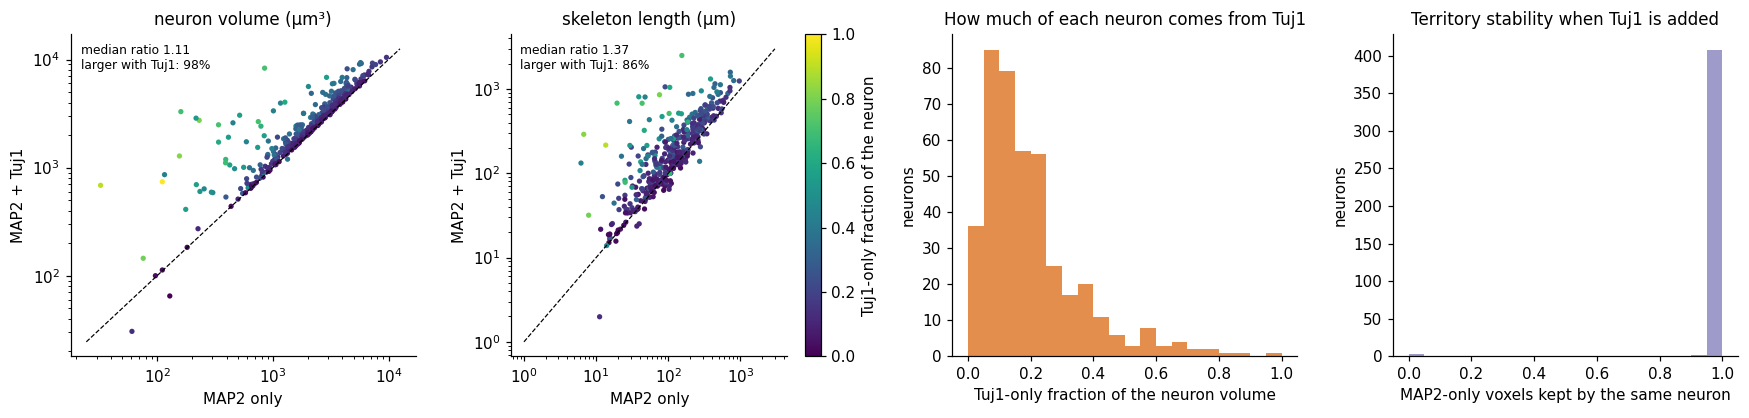

In [14]:
mech = pd.DataFrame(tuj_neu)
pair = mech.pivot_table(index=['image', 'label'], columns='version', values=['volume_um3', 'length_um', 'tips'])
pair.columns = [f'{c} | {v}' for c, v in pair.columns]
ovl = pd.DataFrame([{'image': i, **n} for i, o in tuj_ovl.items() for n in o['neurons']]).set_index(['image', 'label'])
pair = pair.join(ovl)
m, u = 'Mech (MAP2)', 'Mech (MAP2 + Tuj1)'
fig, axs = plt.subplots(1, 4, figsize=(16, 3.9))
for ax, c, l in [(axs[0], 'volume_um3', 'neuron volume (µm³)'), (axs[1], 'length_um', 'skeleton length (µm)')]:
    x, y = pair[f'{c} | {m}'], pair[f'{c} | {u}']
    ax.scatter(x, y, s=12, c=pair['tuj1_only_fraction'], cmap='viridis', vmin=0, vmax=1, edgecolor='none')
    lim = [max(1, np.nanmin([x.min(), y.min()]) * 0.8), np.nanmax([x.max(), y.max()]) * 1.2]
    ax.plot(lim, lim, 'k--', lw=0.8); ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('MAP2 only'); ax.set_ylabel('MAP2 + Tuj1'); ax.set_title(l)
    ax.text(0.03, 0.97, f'median ratio {np.nanmedian(y / x):.2f}\nlarger with Tuj1: {(y > x).mean() * 100:.0f}%', transform=ax.transAxes, va='top', fontsize=8)
sc = axs[1].collections[0]
fig.colorbar(sc, ax=axs[1], label='Tuj1-only fraction of the neuron')
axs[2].hist(pair['tuj1_only_fraction'].dropna(), bins=np.linspace(0, 1, 21), color=VERSIONS[u], alpha=0.7)
axs[2].set_xlabel('Tuj1-only fraction of the neuron volume'); axs[2].set_ylabel('neurons'); axs[2].set_title('How much of each neuron comes from Tuj1')
axs[3].hist(pair['kept_fraction'].dropna(), bins=np.linspace(0, 1, 21), color=VERSIONS[m], alpha=0.7)
axs[3].set_xlabel('MAP2-only voxels kept by the same neuron'); axs[3].set_ylabel('neurons'); axs[3].set_title('Territory stability when Tuj1 is added')
save(fig, 'fig9_tuj1_paired_neurons')
pair.to_csv(os.path.join(OUT, 'per_neuron_tuj1_paired.csv'))

## 6. Network activity: soma-only vs morphology (MAP2 + Tuj1)
For each Mech image `bsb_network.py --tag _sigma2_map2-tuj1` built two networks of the same cells (same soma positions, same neuron
model, synapses and Poisson input):
- **morphology**: each cell its own MAP2 + Tuj1 SWC, connections where skeleton voxels intersect (`VoxelIntersection`);
- **soma only**: no morphology, p(d) = p0·exp(−d²/2σ²) of the soma distance d, with σ fitted to the connected pairs of *that* morphology
  network and p0 set to give the same number of connections. The soma-only network therefore changes with the reconstruction it is
  fitted to (table below: the MAP2-only fit, where it exists, has a different σ and p0).

5 repeats per network (input seeds; the soma-only network is re-drawn each repeat). Dots = images (mean of the repeats), error bars =
SD over repeats, bars = mean over images; lines join the two networks of one image. With 3 images no test is run. The population rate
is repeat 0 (the one stored in `spikes.npz`). Weights, adaptation and input are not fitted to data: compare the two networks, not the
absolute numbers.

In [15]:
NET_DIR = 'results/network'
NET_TAG = TUJ1_TAGS['MAP2 + Tuj1']
NETS = {'soma': ('soma only', '#7f7f7f'), 'morph': ('morphology (MAP2 + Tuj1)', GROUPS['MAP2 + Tuj1'])}
NET_METRICS = [('connections', 'connections'), ('mean_rate_hz', 'mean rate (Hz)'), ('synchrony_chi', 'synchrony χ'),
               ('bursts_per_s', 'network bursts / s'), ('burst_participation', 'cells per burst (fraction)'),
               ('burst_duration_ms', 'burst duration (ms)'), ('spikes_in_bursts', 'spikes in bursts (fraction)'),
               ('cv_isi_median', 'ISI CV (median cell)')]

fits, net_rows, net_spikes = [], [], {}
for im in images:
    if im['group'] != 'Mech':
        continue
    for g, t in TUJ1_TAGS.items():
        d = os.path.join(NET_DIR, im['image'] + t)
        if not os.path.exists(os.path.join(d, 'summary.json')):
            print('no network:', d)
            continue
        s = json.load(open(os.path.join(d, 'summary.json')))
        fits.append({'image': im['image'], 'reconstruction': g, 'neurons': s['neurons'], 'morph connections': s['morph']['connections'],
                     'soma-only connections (repeat 0)': s['soma']['connections'], 'sigma (µm)': s['fit']['sigma_um'], 'p0': s['fit']['p0']})
        if t != NET_TAG or 'runs' not in s['morph']:
            continue
        for key in NETS:
            for r, run in enumerate(s[key]['runs']):
                net_rows.append({'image': im['image'], 'network': key, 'repeat': r,
                                 'connections': run.get('connections', s[key]['connections']), **{k: v for k, v in run.items() if k != 'connections'}})
        sp = np.load(os.path.join(d, 'spikes.npz'))
        net_spikes[im['image']] = {'n': s['neurons'], 'duration': s['params']['duration'], **{k: sp[f'{k}_t'] for k in NETS}}
df_net = pd.DataFrame(net_rows)
df_fits = pd.DataFrame(fits).set_index(['image', 'reconstruction'])
df_fits.round(3)

no network: results/network/IF_D14_Mech_40x_up_Ch1_003_sigma2


neurons  morph connections  \
image                      reconstruction                               
IF_D14_Mech_40x_up_Ch1_002 MAP2                122                416   
                           MAP2 + Tuj1         122                491   
IF_D14_Mech_40x_up_Ch1_003 MAP2 + Tuj1         128                470   
IF_D14_Mech_40x_up_Ch1_004 MAP2                167                345   
                           MAP2 + Tuj1         167                651   

                                           soma-only connections (repeat 0)  \
image                      reconstruction                                     
IF_D14_Mech_40x_up_Ch1_002 MAP2                                         416   
                           MAP2 + Tuj1                                  508   
IF_D14_Mech_40x_up_Ch1_003 MAP2 + Tuj1                                  468   
IF_D14_Mech_40x_up_Ch1_004 MAP2                                         388   
                           MAP2 + Tuj1                                  658   

                                           sigma (µm)     p0  
image                      reconstruction                     
IF_D14_Mech_40x_up_Ch1_002 MAP2                26.132  0.768  
                           MAP2 + Tuj1         29.011  0.761  
IF_D14_Mech_40x_up_Ch1_003 MAP2 + Tuj1         28.113  0.710  
IF_D14_Mech_40x_up_Ch1_004 MAP2                23.794  0.492  
                           MAP2 + Tuj1         35.405  0.456

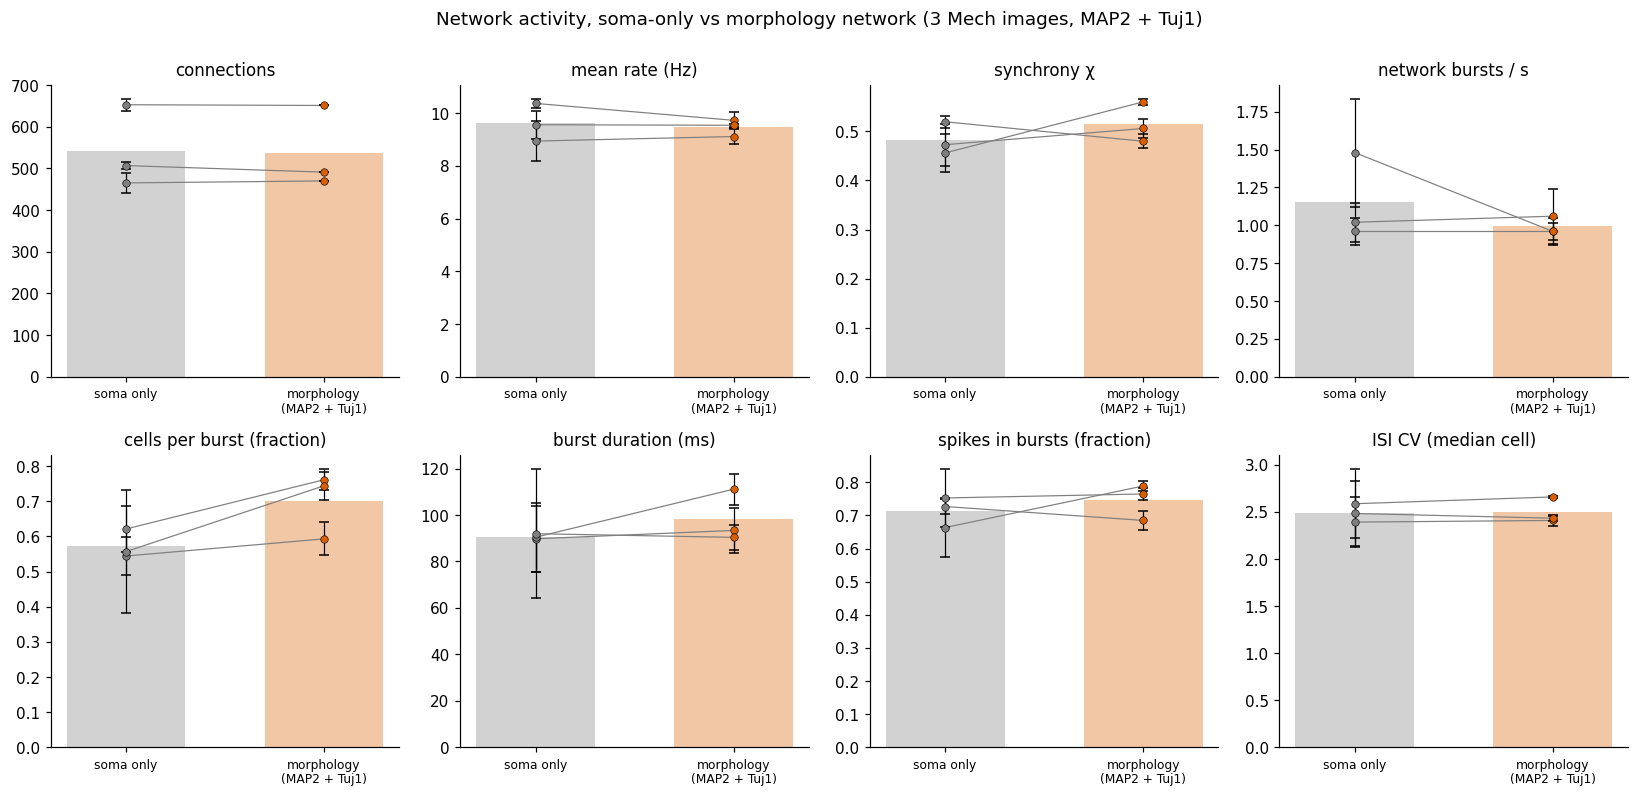

In [16]:
net_img = df_net.groupby(['image', 'network']).agg(['mean', 'std'])
net_images = sorted(df_net['image'].unique())
fig, axs = plt.subplots(2, 4, figsize=(15, 7.2))
for ax, (c, l) in zip(axs.ravel(), NET_METRICS):
    for i, (key, (name, col)) in enumerate(NETS.items()):
        m = np.array([net_img.loc[(im, key), (c, 'mean')] for im in net_images], float)
        sd = np.array([net_img.loc[(im, key), (c, 'std')] for im in net_images], float)
        ax.bar(i, np.nanmean(m), color=col, alpha=0.35, width=0.6)
        ax.errorbar(np.full(len(m), i), m, yerr=sd, fmt='none', ecolor='k', elinewidth=0.8, capsize=3, zorder=3)
        ax.scatter(np.full(len(m), i), m, color=col, s=24, zorder=4, edgecolor='k', lw=0.4)
    for im in net_images:
        ax.plot([0, 1], [net_img.loc[(im, k), (c, 'mean')] for k in NETS], color='0.5', lw=0.8, zorder=2)
    ax.set_xticks(range(len(NETS)), [n.replace(' (', '\n(') for n, _ in NETS.values()], fontsize=8)
    ax.set_title(l)
fig.suptitle(f'Network activity, soma-only vs morphology network ({len(net_images)} Mech images, MAP2 + Tuj1)', y=1.0)
save(fig, 'fig11_network_activity')

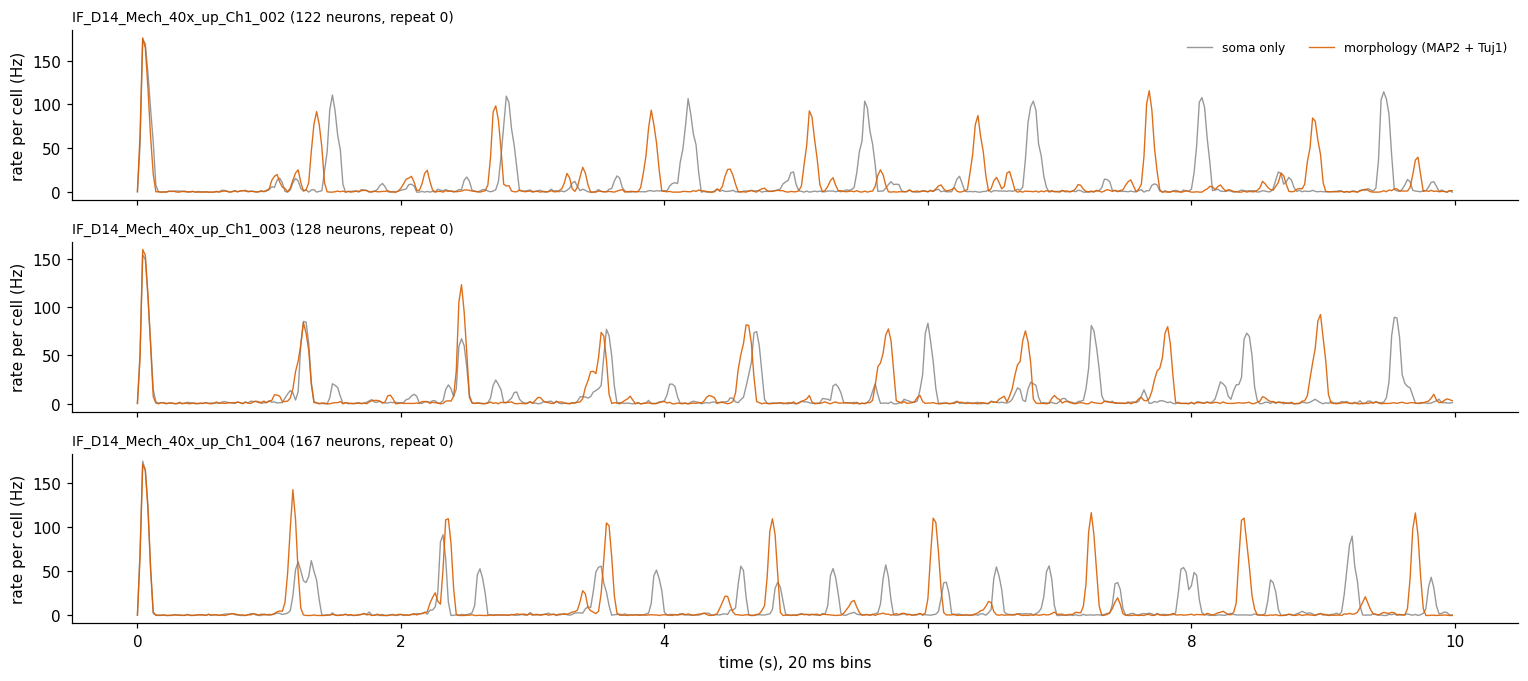

In [17]:
BIN_MS = 20.0
fig, axs = plt.subplots(len(net_spikes), 1, figsize=(14, 2.1 * len(net_spikes)), sharex=True, squeeze=False)
for ax, (im, sp) in zip(axs[:, 0], net_spikes.items()):
    edges = np.arange(0, sp['duration'] + BIN_MS, BIN_MS)
    for key, (name, col) in NETS.items():
        rate = np.histogram(sp[key], edges)[0] / sp['n'] / (BIN_MS / 1000)
        ax.plot(edges[:-1] / 1000, rate, color=col, lw=0.9, label=name, alpha=0.9 if key == 'morph' else 0.8)
    ax.set_ylabel('rate per cell (Hz)')
    ax.set_title(f"{im} ({sp['n']} neurons, repeat 0)", fontsize=9, loc='left')
axs[0, 0].legend(frameon=False, fontsize=8, ncol=2, loc='upper right')
axs[-1, 0].set_xlabel(f'time (s), {BIN_MS:g} ms bins')
save(fig, 'fig12_network_population_rate')

In [18]:
nsum = {}
for c, l in NET_METRICS:
    nsum[l] = {}
    for key, (name, _) in NETS.items():
        v = np.array([net_img.loc[(im, key), (c, 'mean')] for im in net_images], float)
        nsum[l][name] = f'{v.mean():.3g}' if len(v) == 1 else f'{v.mean():.3g} ± {v.std(ddof=1):.2g}'
    q = np.array([net_img.loc[(im, 'morph'), (c, 'mean')] / net_img.loc[(im, 'soma'), (c, 'mean')] for im in net_images], float)
    nsum[l]['ratio morphology / soma only (per image)'] = ', '.join(f'{x:.2f}' for x in q)
net_summary = pd.DataFrame(nsum).T
net_summary.to_csv(os.path.join(OUT, 'summary_network.csv'))
df_fits.to_csv(os.path.join(OUT, 'network_fits.csv'))
df_net.to_csv(os.path.join(OUT, 'network_runs.csv'), index=False)
net_summary

,soma only,morphology (MAP2 + Tuj1),ratio morphology / soma only (per image)
connections,542 ± 99,537 ± 99,"0.97, 1.01, 1.00"
mean rate (Hz),9.63 ± 0.72,9.46 ± 0.32,"0.94, 1.02, 1.00"
synchrony χ,0.483 ± 0.033,0.515 ± 0.041,"0.92, 1.07, 1.23"
network bursts / s,1.15 ± 0.28,0.993 ± 0.058,"1.04, 1.00, 0.65"
cells per burst (fraction),0.574 ± 0.041,0.7 ± 0.093,"1.09, 1.23, 1.34"
burst duration (ms),90.7 ± 1.1,98.3 ± 11,"1.04, 1.23, 0.98"
spikes in bursts (fraction),0.714 ± 0.046,0.746 ± 0.054,"0.94, 1.19, 1.02"
ISI CV (median cell),2.49 ± 0.098,2.5 ± 0.14,"1.03, 1.01, 0.98"
